In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!ls -lah /content/drive/MyDrive | head -50

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ls: '/content/drive/MyDrive/ADAS_17Classes_Dataset (1)': No such file or directory
ls: '/content/drive/MyDrive/ADAS_Training_Results (1)': No such file or directory
ls: /content/drive/MyDrive/ADAS_Training_Results: No such file or directory
ls: /content/drive/MyDrive/ADAS_17Classes_Dataset: No such file or directory
total 4.8G
drwx------ 18 root root 4.0K Sep 14 20:13 .
drwx------  5 root root 4.0K Sep 14 20:13 ..
-rw-------  1 root root  29M Sep  9  2023 1. Physics and Measurement.pdf
-rw-------  1 root root 208K Aug  9  2022 2022080996000067.pdf
-rw-------  1 root root 546K Oct 16  2023 202310323 (1).docx
-rw-------  1 root root  20K Oct 29  2022 202310323_Abdulhamid.pdf
-rw-------  1 root root 1.2M Feb  3  2024 202310323.docx
-rw-------  1 root root  182 Sep 11  2023 202310323.gdoc
-rw-------  1 root root  182 Sep 17  2023 202310323..gdoc
-rw-------  1 roo

In [ ]:
!find /content/drive/MyDrive -type f -iname "*Offline*Arabic*ADAS*"

/content/drive/MyDrive/Offline Arabic ADAS.zip
/content/drive/MyDrive/Offline Arabic ADAS.coco.zip


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Offline Arabic ADAS.coco.zip"
extract_path = "/content/adas_coco"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)

Extracted to: /content/adas_coco


In [ ]:
!find /content/adas_coco -maxdepth 2 -type d

/content/adas_coco
/content/adas_coco/train
/content/adas_coco/valid
/content/adas_coco/test


In [ ]:
import json
import os
import shutil

source_root = "/content/adas_coco"
target_root = "/content/adas_coco_rtdetr"

splits = ["train", "valid", "test"]

category_mapping = {
    1: 0,
    2: 1,
    3: 2,
    4: 3,
    5: 4,
    6: 5,
    7: 6,
    8: 7,
    9: 8,
    10: 9,
    11: 10,
    12: 11,
    13: 12,
    14: 13,
}

new_categories = [
    {"id": 0, "name": "loose_gravel", "supercategory": "ADAS"},
    {"id": 1, "name": "no_entry", "supercategory": "ADAS"},
    {"id": 2, "name": "no_parking_waiting", "supercategory": "ADAS"},
    {"id": 3, "name": "pedestrian", "supercategory": "ADAS"},
    {"id": 4, "name": "pedestrian_crossing_sign", "supercategory": "ADAS"},
    {"id": 5, "name": "speed_100", "supercategory": "ADAS"},
    {"id": 6, "name": "speed_30", "supercategory": "ADAS"},
    {"id": 7, "name": "speed_40", "supercategory": "ADAS"},
    {"id": 8, "name": "speed_50", "supercategory": "ADAS"},
    {"id": 9, "name": "speed_60", "supercategory": "ADAS"},
    {"id": 10, "name": "speed_80", "supercategory": "ADAS"},
    {"id": 11, "name": "speed_bump", "supercategory": "ADAS"},
    {"id": 12, "name": "stoop_sign", "supercategory": "ADAS"},
    {"id": 13, "name": "traffic_signal", "supercategory": "ADAS"},
]

os.makedirs(target_root, exist_ok=True)

for split in splits:
    source_dir = os.path.join(source_root, split)
    target_dir = os.path.join(target_root, split)

    os.makedirs(target_dir, exist_ok=True)

    for filename in os.listdir(source_dir):
        if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            shutil.copy2(
                os.path.join(source_dir, filename),
                os.path.join(target_dir, filename)
            )

    source_json = os.path.join(source_dir, "_annotations.coco.json")
    target_json = os.path.join(target_dir, "_annotations.coco.json")

    with open(source_json, "r", encoding="utf-8") as f:
        coco = json.load(f)

    for annotation in coco["annotations"]:
        old_id = annotation["category_id"]

        if old_id not in category_mapping:
            raise ValueError(
                f"Unexpected category_id {old_id} found in {split}"
            )

        annotation["category_id"] = category_mapping[old_id]

    coco["categories"] = new_categories

    with open(target_json, "w", encoding="utf-8") as f:
        json.dump(coco, f, ensure_ascii=False)

    print(
        f"{split}: {len(coco['images'])} images, "
        f"{len(coco['annotations'])} annotations"
    )

print("\nCreated:", target_root)

train: 6191 images, 8520 annotations
valid: 1767 images, 2405 annotations
test: 884 images, 1278 annotations

Created: /content/adas_coco_rtdetr


In [ ]:
import os

drive_config_dir = "/content/drive/MyDrive/RT-DETR_Training/configs/dataset"
os.makedirs(drive_config_dir, exist_ok=True)

config_path = os.path.join(
    drive_config_dir,
    "adas_detection.yml"
)

config = """task: detection

evaluator:

  type: CocoEvaluator

  iou_types: ['bbox']

num_classes: 14

remap_mscoco_category: False

train_dataloader:

  type: DataLoader

  dataset:

    type: CocoDetection

    img_folder: /content/adas_coco_rtdetr/train

    ann_file: /content/adas_coco_rtdetr/train/_annotations.coco.json

    return_masks: False

    transforms:

      type: Compose

      ops: ~

  shuffle: True

  num_workers: 2

  drop_last: True

  collate_fn: BatchImageCollateFunction

val_dataloader:

  type: DataLoader

  dataset:

    type: CocoDetection

    img_folder: /content/adas_coco_rtdetr/valid

    ann_file: /content/adas_coco_rtdetr/valid/_annotations.coco.json

    return_masks: False

    transforms:

      type: Compose

      ops: ~

  shuffle: False

  num_workers: 2

  drop_last: False

  collate_fn: BatchImageCollateFunction

"""

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config)

print("Saved to Drive:")
print(config_path)

Saved to Drive:
/content/drive/MyDrive/RT-DETR_Training/configs/dataset/adas_detection.yml


In [ ]:
%cd /content/RT-DETR/rtdetrv2_pytorch

/content/RT-DETR/rtdetrv2_pytorch


In [ ]:
!ls configs/rtdetrv2

include				  rtdetrv2_r18vd_sp2_120e_coco.yml
rtdetrv2_hgnetv2_h_6x_coco.yml	  rtdetrv2_r18vd_sp3_120e_coco.yml
rtdetrv2_hgnetv2_l_6x_coco.yml	  rtdetrv2_r34vd_120e_coco.yml
rtdetrv2_hgnetv2_x_6x_coco.yml	  rtdetrv2_r34vd_dsp_1x_coco.yml
rtdetrv2_r101vd_6x_coco.yml	  rtdetrv2_r50vd_6x_coco.yml
rtdetrv2_r18vd_120e_coco.yml	  rtdetrv2_r50vd_dsp_1x_coco.yml
rtdetrv2_r18vd_120e_voc.yml	  rtdetrv2_r50vd_m_7x_coco.yml
rtdetrv2_r18vd_dsp_3x_coco.yml	  rtdetrv2_r50vd_m_dsp_3x_coco.yml
rtdetrv2_r18vd_sp1_120e_coco.yml


In [ ]:
config_path = "/content/RT-DETR/rtdetrv2_pytorch/configs/dataset/adas_detection.yml"

config = """task: detection

evaluator:
  type: CocoEvaluator
  iou_types: ['bbox']

num_classes: 14

remap_mscoco_category: False

train_dataloader:
  type: DataLoader
  dataset:
    type: CocoDetection
    img_folder: /content/adas_coco_rtdetr/train
    ann_file: /content/adas_coco_rtdetr/train/_annotations.coco.json
    return_masks: False
    transforms:
      type: Compose
      ops: ~
  shuffle: True
  num_workers: 2
  drop_last: True
  collate_fn:
    type: BatchImageCollateFunction

val_dataloader:
  type: DataLoader
  dataset:
    type: CocoDetection
    img_folder: /content/adas_coco_rtdetr/valid
    ann_file: /content/adas_coco_rtdetr/valid/_annotations.coco.json
    return_masks: False
    transforms:
      type: Compose
      ops:
        - type: Resize
          size: [640, 640]
        - type: ConvertPILImage
          dtype: float32
          scale: True
  shuffle: False
  num_workers: 2
  drop_last: False
  collate_fn:
    type: BatchImageCollateFunction
"""

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config)

print("Fixed local validation configuration.")

Fixed local validation configuration.


In [ ]:
import shutil
import os

drive_config_dir = "/content/drive/MyDrive/RT-DETR_Training/configs/rtdetrv2"
os.makedirs(drive_config_dir, exist_ok=True)

drive_config_path = os.path.join(
    drive_config_dir,
    "rtdetrv2_adas_s.yml"
)

shutil.copy2(config_path, drive_config_path)

print("Saved to Drive:")
print(drive_config_path)

Saved to Drive:
/content/drive/MyDrive/RT-DETR_Training/configs/rtdetrv2/rtdetrv2_adas_s.yml


In [ ]:
from pathlib import Path
import os
import shutil

source_config = Path("configs/rtdetrv2/rtdetrv2_adas_s.yml")
training_config = Path("configs/rtdetrv2/rtdetrv2_adas_baseline.yml")

content = source_config.read_text(encoding="utf-8")

content = content.replace(
    "output_dir: ./output/rtdetrv2_adas_s",
    "output_dir: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline"
)

content = content.replace(
    "total_batch_size: 16",
    "total_batch_size: 8"
)

training_config.write_text(content, encoding="utf-8")

drive_config_dir = "/content/drive/MyDrive/RT-DETR_Training/configs/rtdetrv2"
os.makedirs(drive_config_dir, exist_ok=True)

drive_config_path = os.path.join(
    drive_config_dir,
    "rtdetrv2_adas_baseline.yml"
)

shutil.copy2(training_config, drive_config_path)

print("Saved to Drive:")
print(drive_config_path)

Saved to Drive:
/content/drive/MyDrive/RT-DETR_Training/configs/rtdetrv2/rtdetrv2_adas_baseline.yml


In [ ]:
import shutil
import os

source = "/content/drive/MyDrive/RT-DETR_Training/configs/dataset/adas_detection.yml"
destination = "/content/RT-DETR/rtdetrv2_pytorch/configs/dataset/adas_detection.yml"

os.makedirs(os.path.dirname(destination), exist_ok=True)
shutil.copy2(source, destination)

print("Copied:")
print(destination)

Copied:
/content/RT-DETR/rtdetrv2_pytorch/configs/dataset/adas_detection.yml


In [ ]:
%cd /content/RT-DETR/rtdetrv2_pytorch

!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True python tools/train.py \
    -c configs/rtdetrv2/rtdetrv2_adas_baseline.yml \
    -r /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/last.pth \
    --use-amp

/content/RT-DETR/rtdetrv2_pytorch
2026-09-14 20:45:12.758481: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
Not init distributed mode.
cfg:  {'task': 'detection', '_model': None, '_postprocessor': None, '_criterion': None, '_optimizer': None, '_lr_scheduler': None, '_lr_warmup_scheduler': None, '_train_dataloader': None, '_val_dataloader': None, '_ema': None, '_scaler': None, '_train_dataset': None, '_val_dataset': None, '_collate_fn': None, '_evaluator': None, '_writer': None, 'num_workers': 0, 'batch_size': None, '_train_batch_size': None, '_val_batch_size': None, '_train_shuffle': None, '_val_shuffle': None, 'resume': '/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/last.pth', 'tuning': None, 'epoches': 120, 'last_epoch': -1, 

/content/RT-DETR/rtdetrv2_pytorch
Load PResNet18 state_dict
Model loaded successfully.
Device: cuda


Saving لقطة شاشة 2026-09-12 162620.png to لقطة شاشة 2026-09-12 162620.png

Uploaded images: 1

Image: لقطة شاشة 2026-09-12 162620.png
Output structure:
<class 'dict'>


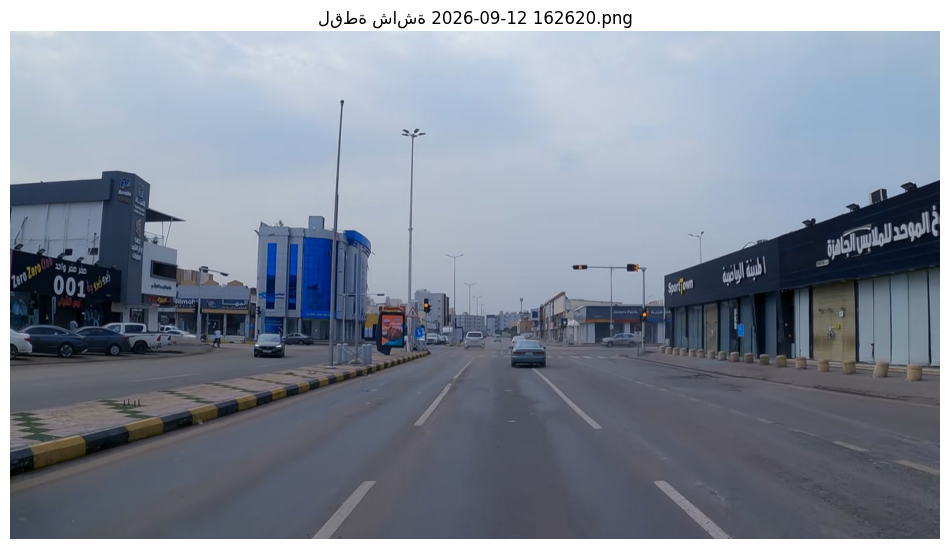

In [ ]:
# Install required packages
!pip install -q opencv-python matplotlib

import os
import sys
import torch
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

# Move to RT-DETR project
%cd /content/RT-DETR/rtdetrv2_pytorch

# Add project to Python path
sys.path.insert(0, "/content/RT-DETR/rtdetrv2_pytorch")

from src.core import YAMLConfig


# =========================
# Configuration
# =========================

CONFIG_PATH = "/content/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_adas_baseline.yml"

WEIGHTS_PATH = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/best.pth"

CONF_THRESHOLD = 0.30


# =========================
# Load model
# =========================

cfg = YAMLConfig(CONFIG_PATH, resume=WEIGHTS_PATH)

checkpoint = torch.load(
    WEIGHTS_PATH,
    map_location="cpu",
    weights_only=False
)

state = checkpoint["ema"]["module"] if "ema" in checkpoint else checkpoint["model"]

cfg.model.load_state_dict(state)

model = cfg.model.deploy()
model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print("Model loaded successfully.")
print("Device:", device)


# =========================
# Upload images
# =========================

uploaded = files.upload()

image_paths = list(uploaded.keys())

print(f"\nUploaded images: {len(image_paths)}")


# =========================
# Class names
# =========================

CLASS_NAMES = [
    "Stop",
    "No Entry",
    "No Parking",
    "No Waiting",
    "Speed Limit",
    "Pedestrian Crossing",
    "Speed Bumps",
    "Loose Gravel",
    "Pedestrian",
    "Pothole",
    "Traffic Light",
    # Add the remaining class names
]


# =========================
# Preprocessing
# =========================

import torchvision.transforms as T

transform = T.Compose([
    T.Resize((640, 640)),
    T.ToTensor()
])


# =========================
# Inference
# =========================

for image_path in image_paths:

    image = Image.open(image_path).convert("RGB")

    original_width, original_height = image.size

    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)

    print(f"\n{'=' * 60}")
    print("Image:", image_path)
    print("Output structure:")
    print(type(outputs))

    # Display original image
    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis("off")
    plt.title(image_path)
    plt.show()

In [ ]:
print(outputs.keys())

for key, value in outputs.items():
    if torch.is_tensor(value):
        print(key, value.shape, value.dtype)
    else:
        print(key, type(value))

dict_keys(['pred_logits', 'pred_boxes'])
pred_logits torch.Size([1, 300, 14]) torch.float32
pred_boxes torch.Size([1, 300, 4]) torch.float32


In [ ]:
print("pred_logits shape:", outputs["pred_logits"].shape)

print("\nLogits range:")
print("min:", outputs["pred_logits"].min().item())
print("max:", outputs["pred_logits"].max().item())

print("\nFirst prediction:")
print(outputs["pred_logits"][0, 0])

print("\nModel config:")
print(cfg)

pred_logits shape: torch.Size([1, 300, 14])

Logits range:
min: -7.564043045043945
max: 0.27178001403808594

First prediction:
tensor([-5.2264, -4.2898, -4.9332,  0.2718, -4.1647, -5.1147, -4.5250, -4.6911,
        -5.2163, -4.3204, -4.4504, -4.3571, -4.1995, -4.4140], device='cuda:0')

Model config:
task: detection
num_workers: 0
batch_size: None
resume: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/best.pth
tuning: None
epoches: 120
last_epoch: -1
use_amp: True
use_ema: True
ema_decay: 0.9999
ema_warmups: 2000
sync_bn: True
clip_max_norm: 0.1
find_unused_parameters: False
seed: None
print_freq: 100
checkpoint_freq: 1
output_dir: /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline
summary_dir: None
device: 
yaml_cfg: {'task': 'detection', 'evaluator': {'type': 'CocoEvaluator', 'iou_types': ['bbox']}, 'num_classes': 14, 'remap_mscoco_category': False, 'train_dataloader': {'type': 'DataLoader', 'dataset': {'type': 'CocoDetection', 'img_folder': '/content/adas

In [ ]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import files
import torchvision.transforms as T


CONF_THRESHOLD = 0.30


# Upload images
uploaded = files.upload()


# Validation preprocessing
transform = T.Compose([
    T.Resize((640, 640)),
    T.ToTensor()
])


# Get the official RT-DETR postprocessor
postprocessor = cfg.postprocessor


for image_path in uploaded.keys():

    image = Image.open(image_path).convert("RGB")

    original_width, original_height = image.size

    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():

        outputs = model(image_tensor)

        # Use RT-DETR's official postprocessor
        results = postprocessor(
            outputs,
            torch.tensor(
                [[original_width, original_height]],
                device=device
            )
        )


    print("\n" + "=" * 60)
    print("Image:", image_path)

    print("Result type:", type(results))

    if isinstance(results, dict):
        print("Result keys:", results.keys())

        for key, value in results.items():
            if torch.is_tensor(value):
                print(key, value.shape)


    elif isinstance(results, (list, tuple)):
        print("Number of result elements:", len(results))

        for i, value in enumerate(results):
            if torch.is_tensor(value):
                print(i, value.shape)
            else:
                print(i, type(value))

Saving لقطة شاشة 2026-09-12 162620.png to لقطة شاشة 2026-09-12 162620 (2).png

Image: لقطة شاشة 2026-09-12 162620 (2).png
Result type: <class 'list'>
Number of result elements: 1
0 <class 'dict'>


In [ ]:
result = results[0]

print("Result keys:", result.keys())

for key, value in result.items():
    if torch.is_tensor(value):
        print(f"{key}: shape={value.shape}, dtype={value.dtype}")
        print(value[:10])
    else:
        print(f"{key}: {type(value)}")

Result keys: dict_keys(['labels', 'boxes', 'scores'])
labels: shape=torch.Size([300]), dtype=torch.int64
tensor([ 3,  3,  3, 13,  2,  3,  3,  3,  3,  3], device='cuda:0')
boxes: shape=torch.Size([300, 4]), dtype=torch.float32
tensor([[278.1329, 407.3568, 288.9006, 434.0268],
        [ 80.7331, 394.1596,  94.4165, 412.2507],
        [259.3781, 411.5010, 267.5553, 426.9984],
        [566.5046, 366.7622, 579.1411, 386.4336],
        [555.6501, 402.4884, 570.3452, 423.1238],
        [273.1224, 409.7451, 281.6411, 433.0679],
        [894.4455, 419.4836, 905.7460, 441.3530],
        [263.9595, 410.9016, 272.2913, 427.8781],
        [763.0538, 415.2929, 770.1491, 430.8210],
        [284.1885, 409.9169, 291.3072, 432.9310]], device='cuda:0')
scores: shape=torch.Size([300]), dtype=torch.float32
tensor([0.5675, 0.5328, 0.2372, 0.2059, 0.1375, 0.1249, 0.1042, 0.1021, 0.0948,
        0.0926], device='cuda:0')


In [ ]:
import json

json_path = "/content/adas_coco_rtdetr/train/_annotations.coco.json"

with open(json_path, "r") as f:
    data = json.load(f)

print("Categories:")
for category in data["categories"]:
    print(category["id"], "->", category["name"])

Categories:
0 -> loose_gravel
1 -> no_entry
2 -> no_parking_waiting
3 -> pedestrian
4 -> pedestrian_crossing_sign
5 -> speed_100
6 -> speed_30
7 -> speed_40
8 -> speed_50
9 -> speed_60
10 -> speed_80
11 -> speed_bump
12 -> stoop_sign
13 -> traffic_signal


Saving لقطة شاشة 2026-09-07 162559.png to لقطة شاشة 2026-09-07 162559.png


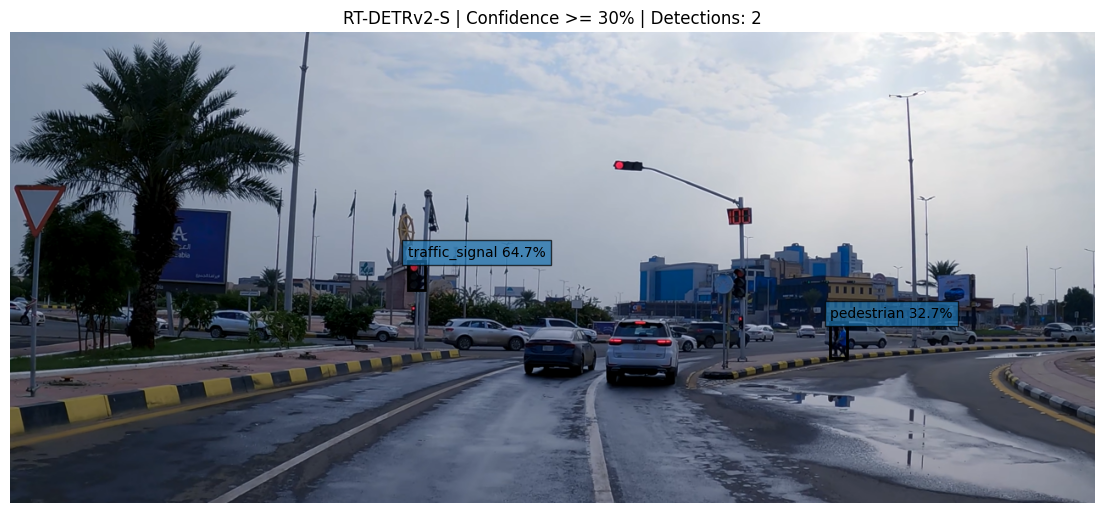

Image: لقطة شاشة 2026-09-07 162559.png
Detections: 2
traffic_signal            |  64.75% | Box: [468.8, 269.9, 488.8, 304.7]
pedestrian                |  32.71% | Box: [967.1, 341.9, 986.7, 384.2]


In [ ]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import files
import torchvision.transforms as T

CONF_THRESHOLD = 0.30

CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

uploaded = files.upload()

transform = T.Compose([
    T.Resize((640, 640)),
    T.ToTensor()
])

postprocessor = cfg.postprocessor

for image_path in uploaded.keys():

    image = Image.open(image_path).convert("RGB")
    original_width, original_height = image.size

    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)

        results = postprocessor(
            outputs,
            torch.tensor(
                [[original_width, original_height]],
                device=device
            )
        )

    result = results[0]

    labels = result["labels"].cpu()
    boxes = result["boxes"].cpu()
    scores = result["scores"].cpu()

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(image)

    detection_count = 0

    for label, box, score in zip(labels, boxes, scores):

        if score < CONF_THRESHOLD:
            continue

        x1, y1, x2, y2 = box.tolist()

        class_id = int(label)
        class_name = CLASS_NAMES.get(class_id, f"class_{class_id}")

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            fill=False
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 5),
            f"{class_name} {score * 100:.1f}%",
            fontsize=10,
            bbox=dict(alpha=0.7)
        )

        detection_count += 1

    ax.axis("off")

    title = (
        f"RT-DETRv2-S | Confidence >= {CONF_THRESHOLD:.0%} | "
        f"Detections: {detection_count}"
    )

    plt.title(title)
    plt.show()

    print("=" * 60)
    print("Image:", image_path)
    print("Detections:", detection_count)

    for label, box, score in zip(labels, boxes, scores):

        if score < CONF_THRESHOLD:
            continue

        class_id = int(label)
        class_name = CLASS_NAMES.get(class_id, f"class_{class_id}")

        print(
            f"{class_name:25s} | "
            f"{score * 100:6.2f}% | "
            f"Box: {[round(v, 1) for v in box.tolist()]}"
        )

Saving لقطة شاشة 2026-09-07 162802.png to لقطة شاشة 2026-09-07 162802.png


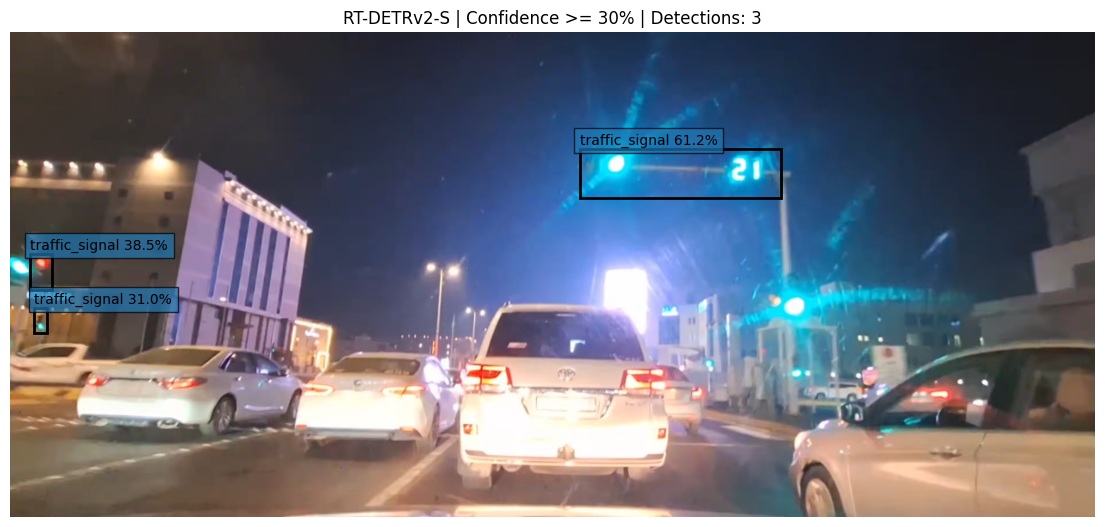

Image: لقطة شاشة 2026-09-07 162802.png
Detections: 3
traffic_signal            |  61.22% | Box: [660.9, 135.2, 895.2, 192.6]
traffic_signal            |  38.54% | Box: [23.0, 256.9, 48.6, 298.6]
traffic_signal            |  30.99% | Box: [27.9, 319.8, 43.0, 348.4]


In [ ]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import files
import torchvision.transforms as T

CONF_THRESHOLD = 0.30

CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

uploaded = files.upload()

transform = T.Compose([
    T.Resize((640, 640)),
    T.ToTensor()
])

postprocessor = cfg.postprocessor

for image_path in uploaded.keys():

    image = Image.open(image_path).convert("RGB")
    original_width, original_height = image.size

    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)

        results = postprocessor(
            outputs,
            torch.tensor(
                [[original_width, original_height]],
                device=device
            )
        )

    result = results[0]

    labels = result["labels"].cpu()
    boxes = result["boxes"].cpu()
    scores = result["scores"].cpu()

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(image)

    detection_count = 0

    for label, box, score in zip(labels, boxes, scores):

        if score < CONF_THRESHOLD:
            continue

        x1, y1, x2, y2 = box.tolist()

        class_id = int(label)
        class_name = CLASS_NAMES.get(class_id, f"class_{class_id}")

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            fill=False
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 5),
            f"{class_name} {score * 100:.1f}%",
            fontsize=10,
            bbox=dict(alpha=0.7)
        )

        detection_count += 1

    ax.axis("off")

    title = (
        f"RT-DETRv2-S | Confidence >= {CONF_THRESHOLD:.0%} | "
        f"Detections: {detection_count}"
    )

    plt.title(title)
    plt.show()

    print("=" * 60)
    print("Image:", image_path)
    print("Detections:", detection_count)

    for label, box, score in zip(labels, boxes, scores):

        if score < CONF_THRESHOLD:
            continue

        class_id = int(label)
        class_name = CLASS_NAMES.get(class_id, f"class_{class_id}")

        print(
            f"{class_name:25s} | "
            f"{score * 100:6.2f}% | "
            f"Box: {[round(v, 1) for v in box.tolist()]}"
        )

Saving لقطة شاشة 2026-09-07 170925.png to لقطة شاشة 2026-09-07 170925.png


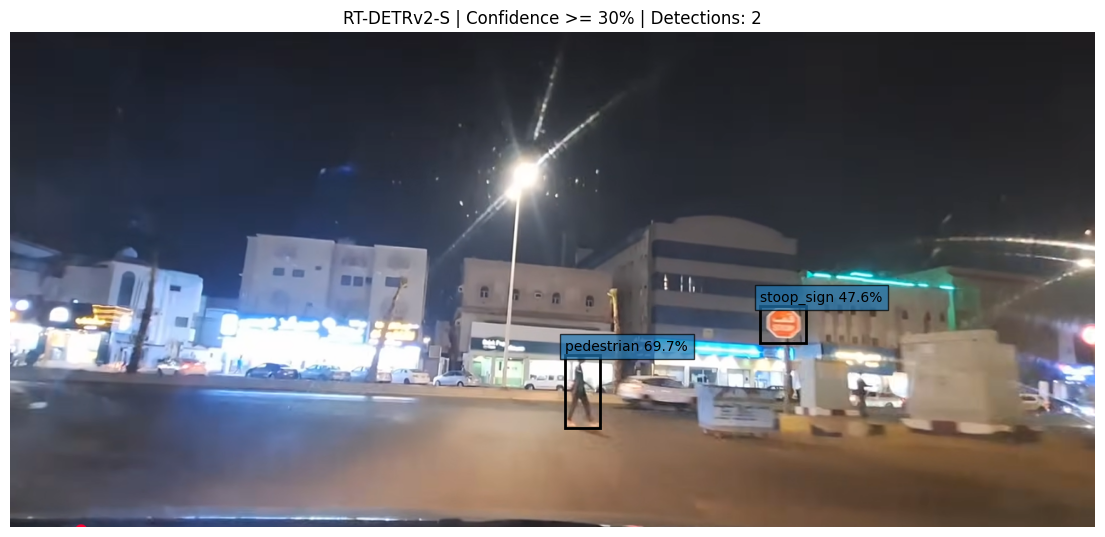

Image: لقطة شاشة 2026-09-07 170925.png
Detections: 2
pedestrian                |  69.66% | Box: [650.4, 377.5, 691.7, 462.9]
stoop_sign                |  47.56% | Box: [878.9, 320.3, 932.5, 363.6]


In [ ]:
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from google.colab import files
import torchvision.transforms as T

CONF_THRESHOLD = 0.30

CLASS_NAMES = {
    0: "loose_gravel",
    1: "no_entry",
    2: "no_parking_waiting",
    3: "pedestrian",
    4: "pedestrian_crossing_sign",
    5: "speed_100",
    6: "speed_30",
    7: "speed_40",
    8: "speed_50",
    9: "speed_60",
    10: "speed_80",
    11: "speed_bump",
    12: "stoop_sign",
    13: "traffic_signal"
}

uploaded = files.upload()

transform = T.Compose([
    T.Resize((640, 640)),
    T.ToTensor()
])

postprocessor = cfg.postprocessor

for image_path in uploaded.keys():

    image = Image.open(image_path).convert("RGB")
    original_width, original_height = image.size

    image_tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)

        results = postprocessor(
            outputs,
            torch.tensor(
                [[original_width, original_height]],
                device=device
            )
        )

    result = results[0]

    labels = result["labels"].cpu()
    boxes = result["boxes"].cpu()
    scores = result["scores"].cpu()

    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(image)

    detection_count = 0

    for label, box, score in zip(labels, boxes, scores):

        if score < CONF_THRESHOLD:
            continue

        x1, y1, x2, y2 = box.tolist()

        class_id = int(label)
        class_name = CLASS_NAMES.get(class_id, f"class_{class_id}")

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            fill=False
        )

        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 5),
            f"{class_name} {score * 100:.1f}%",
            fontsize=10,
            bbox=dict(alpha=0.7)
        )

        detection_count += 1

    ax.axis("off")

    title = (
        f"RT-DETRv2-S | Confidence >= {CONF_THRESHOLD:.0%} | "
        f"Detections: {detection_count}"
    )

    plt.title(title)
    plt.show()

    print("=" * 60)
    print("Image:", image_path)
    print("Detections:", detection_count)

    for label, box, score in zip(labels, boxes, scores):

        if score < CONF_THRESHOLD:
            continue

        class_id = int(label)
        class_name = CLASS_NAMES.get(class_id, f"class_{class_id}")

        print(
            f"{class_name:25s} | "
            f"{score * 100:6.2f}% | "
            f"Box: {[round(v, 1) for v in box.tolist()]}"
        )

In [ ]:
!find /content/RT-DETR -iname "*onnx*" -o -iname "*export*"

/content/RT-DETR/rtdetrv2_pytorch/tools/onnx2trt.sh
/content/RT-DETR/rtdetrv2_pytorch/tools/export_trt.py
/content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py
/content/RT-DETR/rtdetrv2_pytorch/references/deploy/rtdetrv2_onnxruntime.py
/content/RT-DETR/benchmark/yolov8_onnx.py
/content/RT-DETR/rtdetr_paddle/tools/export_model.py
/content/RT-DETR/rtdetr_paddle/ppdet/engine/export_utils.py
/content/RT-DETR/rtdetr_pytorch/tools/export_onnx.py


In [ ]:
!python /content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py --help

usage: export_onnx.py [-h] [--config CONFIG] [--resume RESUME]
                      [--output_file OUTPUT_FILE] [--input_size INPUT_SIZE]
                      [--check] [--simplify] [--update UPDATE [UPDATE ...]]

options:
  -h, --help            show this help message and exit
  --config, -c CONFIG
  --resume, -r RESUME
  --output_file, -o OUTPUT_FILE
  --input_size, -s INPUT_SIZE
  --check
  --simplify
  --update, -u UPDATE [UPDATE ...]
                        update yaml config


In [ ]:
!pip install -q onnxsim
!python /content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py \
    --config /content/RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_adas_baseline.yml \
    --resume /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/best.pth \
    --output_file /content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx \
    --input_size 640 \
    --check \
    --simplify

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 75.1 MB/s eta 0:00:00
Load PResNet18 state_dict
/content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py:58: UserWarning: Exporting a model while it is in training mode. Please ensure that this is intended, as it may lead to different behavior during inference. Calling model.eval() before export is recommended.
  torch.onnx.export(
/content/RT-DETR/rtdetrv2_pytorch/tools/export_onnx.py:58: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(
W0914 21:59:56.731000 38420 torch/onnx/_internal/exporter/_compat.py:133] Setting ONNX exporter to use operator set version 18 because the requested opset_version 16 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested

In [ ]:
import os
import onnx

onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"

print("Exists:", os.path.exists(onnx_path))

if os.path.exists(onnx_path):
    print("Size:", round(os.path.getsize(onnx_path) / (1024**2), 2), "MB")

    model = onnx.load(onnx_path)
    onnx.checker.check_model(model)

    print("ONNX check: PASSED")
    print("Opset:", model.opset_import[0].version)

Exists: True
Size: 76.47 MB
ONNX check: PASSED
Opset: 18


In [ ]:
from google.colab import files

uploaded = files.upload()

image_path = next(iter(uploaded))
print("Uploaded image:", image_path)

Saving لقطة شاشة 2026-09-07 170925.png to لقطة شاشة 2026-09-07 170925 (1).png
Uploaded image: لقطة شاشة 2026-09-07 170925 (1).png


In [ ]:
import onnxruntime as ort
import numpy as np
from PIL import Image

# Paths
onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"
image_path = "لقطة شاشة 2026-09-07 170925 (1).png"

# Load ONNX model
session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# Load image
image = Image.open(image_path).convert("RGB")
original_width, original_height = image.size

print("Original image size:", original_width, "x", original_height)

# Resize image
image_resized = image.resize((640, 640))

# Convert to NumPy
image_np = np.array(image_resized).astype(np.float32) / 255.0

# HWC -> CHW
image_np = np.transpose(image_np, (2, 0, 1))

# Add batch dimension
image_np = np.expand_dims(image_np, axis=0)

# Original image size for RT-DETR postprocessor
orig_target_sizes = np.array(
    [[original_height, original_width]],
    dtype=np.int64
)

# Run ONNX inference
outputs = session.run(
    None,
    {
        "images": image_np,
        "orig_target_sizes": orig_target_sizes
    }
)

labels = outputs[0][0]
boxes = outputs[1][0]
scores = outputs[2][0]

print("\nInference completed.")
print("Labels shape:", labels.shape)
print("Boxes shape:", boxes.shape)
print("Scores shape:", scores.shape)

Original image size: 1272 x 580

Inference completed.
Labels shape: (300,)
Boxes shape: (300, 4)
Scores shape: (300,)


In [ ]:
CLASS_NAMES = [
    "loose_gravel",
    "no_entry",
    "no_parking_waiting",
    "pedestrian",
    "pedestrian_crossing_sign",
    "speed_100",
    "speed_30",
    "speed_40",
    "speed_50",
    "speed_60",
    "speed_80",
    "speed_bump",
    "stoop_sign",
    "traffic_signal"
]

CONF_THRESHOLD = 0.30

print("=" * 60)
print("ONNX RT-DETRv2-S DETECTIONS")
print("=" * 60)

count = 0

for label, box, score in zip(labels, boxes, scores):

    if score >= CONF_THRESHOLD:

        class_id = int(label)
        class_name = CLASS_NAMES[class_id]

        print(
            f"{class_name:28s} | "
            f"{score * 100:6.2f}% | "
            f"Box: [{box[0]:.1f}, {box[1]:.1f}, "
            f"{box[2]:.1f}, {box[3]:.1f}]"
        )

        count += 1

print("=" * 60)
print(f"Detections above {CONF_THRESHOLD * 100:.0f}%: {count}")

ONNX RT-DETRv2-S DETECTIONS
pedestrian                   |  78.32% | Box: [296.6, 826.9, 315.4, 1014.9]
stoop_sign                   |  45.46% | Box: [400.7, 702.6, 425.2, 797.2]
Detections above 30%: 2


In [ ]:
import onnxruntime as ort
import numpy as np
from PIL import Image

onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"
image_path = "لقطة شاشة 2026-09-07 170925 (1).png"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

image = Image.open(image_path).convert("RGB")

original_width, original_height = image.size

print("Original image size:", original_width, "x", original_height)

image_resized = image.resize((640, 640))

image_np = np.array(image_resized).astype(np.float32) / 255.0
image_np = np.transpose(image_np, (2, 0, 1))
image_np = np.expand_dims(image_np, axis=0)

# IMPORTANT: RT-DETR expects [height, width]
orig_target_sizes = np.array(
    [[original_height, original_width]],
    dtype=np.int64
)

outputs = session.run(
    None,
    {
        "images": image_np,
        "orig_target_sizes": orig_target_sizes
    }
)

labels = outputs[0][0]
boxes = outputs[1][0]
scores = outputs[2][0]

print("\nInference completed.")
print("Labels shape:", labels.shape)
print("Boxes shape:", boxes.shape)
print("Scores shape:", scores.shape)

Original image size: 1272 x 580

Inference completed.
Labels shape: (300,)
Boxes shape: (300, 4)
Scores shape: (300,)


In [ ]:
CLASS_NAMES = [
    "loose_gravel",
    "no_entry",
    "no_parking_waiting",
    "pedestrian",
    "pedestrian_crossing_sign",
    "speed_100",
    "speed_30",
    "speed_40",
    "speed_50",
    "speed_60",
    "speed_80",
    "speed_bump",
    "stoop_sign",
    "traffic_signal"
]

CONF_THRESHOLD = 0.30

print("=" * 60)
print("ONNX RT-DETRv2-S DETECTIONS")
print("=" * 60)

count = 0

for label, box, score in zip(labels, boxes, scores):

    if score >= CONF_THRESHOLD:

        class_id = int(label)
        class_name = CLASS_NAMES[class_id]

        print(
            f"{class_name:28s} | "
            f"{score * 100:6.2f}% | "
            f"Box: [{box[0]:.1f}, {box[1]:.1f}, "
            f"{box[2]:.1f}, {box[3]:.1f}]"
        )

        count += 1

print("=" * 60)
print(f"Detections above {CONF_THRESHOLD * 100:.0f}%: {count}")

ONNX RT-DETRv2-S DETECTIONS
pedestrian                   |  78.32% | Box: [296.6, 826.9, 315.4, 1014.9]
stoop_sign                   |  45.46% | Box: [400.7, 702.6, 425.2, 797.2]
Detections above 30%: 2


In [ ]:
import onnxruntime as ort
import numpy as np
from PIL import Image

onnx_path = "/content/drive/MyDrive/RT-DETR_Training/rtdetrv2_adas_baseline/rtdetrv2_adas.onnx"
image_path = "لقطة شاشة 2026-09-07 170925 (1).png"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

image = Image.open(image_path).convert("RGB")

original_width, original_height = image.size

print("Original image size:", original_width, "x", original_height)

image_resized = image.resize((640, 640))

image_np = np.array(image_resized).astype(np.float32) / 255.0
image_np = np.transpose(image_np, (2, 0, 1))
image_np = np.expand_dims(image_np, axis=0)

# RT-DETR postprocessor expects [width, height]
orig_target_sizes = np.array(
    [[original_width, original_height]],
    dtype=np.int64
)

outputs = session.run(
    None,
    {
        "images": image_np,
        "orig_target_sizes": orig_target_sizes
    }
)

labels = outputs[0][0]
boxes = outputs[1][0]
scores = outputs[2][0]

print("\nInference completed.")
print("Labels shape:", labels.shape)
print("Boxes shape:", boxes.shape)
print("Scores shape:", scores.shape)

Original image size: 1272 x 580

Inference completed.
Labels shape: (300,)
Boxes shape: (300, 4)
Scores shape: (300,)


In [ ]:
CLASS_NAMES = [
    "loose_gravel",
    "no_entry",
    "no_parking_waiting",
    "pedestrian",
    "pedestrian_crossing_sign",
    "speed_100",
    "speed_30",
    "speed_40",
    "speed_50",
    "speed_60",
    "speed_80",
    "speed_bump",
    "stoop_sign",
    "traffic_signal"
]

CONF_THRESHOLD = 0.30

print("=" * 60)
print("ONNX RT-DETRv2-S DETECTIONS")
print("=" * 60)

count = 0

for label, box, score in zip(labels, boxes, scores):

    if score >= CONF_THRESHOLD:

        class_id = int(label)
        class_name = CLASS_NAMES[class_id]

        print(
            f"{class_name:28s} | "
            f"{score * 100:6.2f}% | "
            f"Box: [{box[0]:.1f}, {box[1]:.1f}, "
            f"{box[2]:.1f}, {box[3]:.1f}]"
        )

        count += 1

print("=" * 60)
print(f"Detections above {CONF_THRESHOLD * 100:.0f}%: {count}")

ONNX RT-DETRv2-S DETECTIONS
pedestrian                   |  78.32% | Box: [650.6, 377.1, 691.6, 462.8]
stoop_sign                   |  45.46% | Box: [878.9, 320.4, 932.5, 363.5]
Detections above 30%: 2
